# 🌾 Deteksi Penyakit Padi Menggunakan CNN
### Notebook dengan Penjelasan Bahasa Indonesia
**Framework**: TensorFlow / Keras  
**Metode**: Convolutional Neural Network (CNN)  
**Dataset**: Rice Disease Dataset (dimuat dari Google Drive)

---

## 📁 BAGIAN 1: Menghubungkan Google Drive & Menyiapkan Dataset

Sebelum menjalankan kode, pastikan dataset sudah diunggah ke Google Drive dengan struktur folder seperti ini:
```
MyDrive/
└── rice_disease_dataset/
    ├── Bacterial_Leaf_Blight/
    │   ├── gambar1.jpg
    │   └── ...
    ├── Brown_Spot/
    │   └── ...
    ├── Leaf_Smut/
    │   └── ...
    └── Healthy/
        └── ...
```
> ⚠️ **Penting**: Nama folder = nama kelas penyakit. Sesuaikan `DATASET_PATH` di bawah dengan lokasi folder dataset Anda di Google Drive.

In [1]:

# LANGKAH 1: menghubungkan Google Colab dengan Google Drive

#from google.colab import drive
#drive.mount('/content/drive')

#print("✅ Google Drive berhasil terhubung!")

In [2]:
# LANGKAH 2: menentukan lokasi dataset di lokal
import os
from pathlib import Path

DATASET_PATH = r"C:/Users/farid/Downloads/archive (5)/rice_leaf_disease_project/data/rice_leaf_aug_6_no_tungro"  # Dataset 6 kelas tanpa Tungro
dataset_dir = Path(DATASET_PATH)

# Verifikasi bahwa folder dataset ditemukan dan berisi subfolder kelas
if not dataset_dir.exists():
    raise FileNotFoundError(f"Folder dataset tidak ditemukan: {dataset_dir}")

class_dirs = [p for p in dataset_dir.iterdir() if p.is_dir()]
if not class_dirs:
    raise ValueError(f"Tidak ada subfolder kelas di: {dataset_dir}")

print("✅ Folder dataset ditemukan!")
print(f"📂 Lokasi dataset: {dataset_dir}")
print(f"📁 Jumlah kelas (subfolder): {len(class_dirs)}")
print("📌 Contoh kelas:")
for p in sorted(class_dirs)[:10]:
    print(f"   - {p.name}")

✅ Folder dataset ditemukan!
📂 Lokasi dataset: C:\Users\farid\Downloads\archive (5)\rice_leaf_disease_project\data\rice_leaf_aug_6_no_tungro
📁 Jumlah kelas (subfolder): 6
📌 Contoh kelas:
   - Bacterial Leaf Blight
   - Brown Spot
   - Healthy Rice Leaf
   - Leaf Blast
   - Leaf scald
   - Sheath Blight


## 📦 BAGIAN 2: Import Library

Di bagian ini kita mengimpor semua library (pustaka) yang dibutuhkan selama proses pelatihan model.

In [3]:

# Import library yang dibutuhkan


import numpy as np                          # Untuk operasi matematika dan array
import matplotlib.pyplot as plt             # Untuk membuat grafik dan visualisasi
import tensorflow as tf                     # Framework utama deep learning
from tensorflow import keras               # API tingkat tinggi untuk membangun model
from tensorflow.keras import layers        # Kumpulan layer untuk membangun CNN
from sklearn.metrics import confusion_matrix  # Untuk membuat confusion matrix
import warnings
warnings.filterwarnings('ignore')

print(f"✅ TensorFlow versi: {tf.__version__}")
print(f"✅ GPU tersedia: {len(tf.config.list_physical_devices('GPU')) > 0}")
print("✅ Semua library berhasil diimport!")

✅ TensorFlow versi: 2.10.1
✅ GPU tersedia: False
✅ Semua library berhasil diimport!


## ⚙️ BAGIAN 3: Konfigurasi Parameter

Di sini kita menentukan nilai-nilai pengaturan yang akan digunakan sepanjang proses pelatihan.

In [4]:
# Pengaturan global model

IMG_SIZE    = 256   # Ukuran gambar yang akan diproses (256x256 piksel)
                    # Semua gambar akan diubah ukurannya menjadi 256x256

BATCH_SIZE  = 32    # Jumlah gambar yang diproses sekaligus dalam satu iterasi
                    # Nilai lebih besar = lebih cepat, tapi butuh RAM lebih banyak

EPOCHS      = 100    # Jumlah perulangan pelatihan pada seluruh dataset
                    # Nilai lebih besar = model belajar lebih lama

print("⚙️ Konfigurasi model:")
print(f"   Ukuran gambar : {IMG_SIZE} x {IMG_SIZE} piksel")
print(f"   Batch size    : {BATCH_SIZE} gambar/batch")
print(f"   Epochs        : {EPOCHS} epoch")

⚙️ Konfigurasi model:
   Ukuran gambar : 256 x 256 piksel
   Batch size    : 32 gambar/batch
   Epochs        : 100 epoch


## 🖼️ BAGIAN 4: Load & Persiapan Dataset

Dataset dimuat dari Google Drive dan dibagi menjadi **3 bagian**:
- **Training set (70%)**: Data yang digunakan untuk melatih model
- **Validation set (15%)**: Data untuk memantau performa selama pelatihan
- **Test set (15%)**: Data yang TIDAK pernah dilihat model, untuk evaluasi akhir

> 📌 Pembagian 70/15/15 adalah praktik terbaik dalam deep learning agar evaluasi akhir benar-benar objektif.

In [5]:
# Load dataset training (70% dari total data)

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.3,   # 30% data dijadikan val+test, 70% untuk training
    subset='training',
    seed=123,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

print("✅ Dataset training berhasil dimuat!")

Found 3829 files belonging to 6 classes.
Using 2681 files for training.
✅ Dataset training berhasil dimuat!


In [6]:
# Load sisa 30% data (akan dibagi lagi menjadi validasi dan test)

val_test_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.3,   # 30% sisanya
    subset='validation',
    seed=123,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

print("✅ Dataset val+test berhasil dimuat!")

Found 3829 files belonging to 6 classes.
Using 1148 files for validation.
✅ Dataset val+test berhasil dimuat!


In [7]:
# Ambil nama kelas dan informasi dataset
# class_names berisi daftar nama kelas penyakit padi yang diambil otomatis dari nama subfolder dataset

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

print(f"📌 Jumlah kelas penyakit : {NUM_CLASSES}")
print(f"📌 Nama kelas           :")
for i, nama in enumerate(class_names):
    print(f"   [{i}] {nama}")

📌 Jumlah kelas penyakit : 6
📌 Nama kelas           :
   [0] Bacterial Leaf Blight
   [1] Brown Spot
   [2] Healthy Rice Leaf
   [3] Leaf Blast
   [4] Leaf scald
   [5] Sheath Blight


In [8]:
# Bagi 30% tersebut menjadi validation (15%) dan test (15%)
# Caranya: ambil separuh batch untuk val, separuh lagi untuk test

val_test_batches = tf.data.experimental.cardinality(val_test_ds)
test_ds          = val_test_ds.take(val_test_batches // 2)   # 15%
val_ds_final     = val_test_ds.skip(val_test_batches // 2)   # 15%

n_train = tf.data.experimental.cardinality(train_ds).numpy()
n_val   = tf.data.experimental.cardinality(val_ds_final).numpy()
n_test  = tf.data.experimental.cardinality(test_ds).numpy()

print(f"📊 Jumlah batch training   : {n_train}  (~{n_train * BATCH_SIZE} gambar, 70%)")
print(f"📊 Jumlah batch validasi   : {n_val}   (~{n_val  * BATCH_SIZE} gambar, 15%)")
print(f"📊 Jumlah batch testing    : {n_test}   (~{n_test * BATCH_SIZE} gambar, 15%)")
print("\n⚠️  Test set TIDAK digunakan selama training — hanya untuk evaluasi akhir!")

📊 Jumlah batch training   : 84  (~2688 gambar, 70%)
📊 Jumlah batch validasi   : 18   (~576 gambar, 15%)
📊 Jumlah batch testing    : 18   (~576 gambar, 15%)

⚠️  Test set TIDAK digunakan selama training — hanya untuk evaluasi akhir!


## 🔍 BAGIAN 5: Eksplorasi Data (EDA)

Sebelum melatih model, menampilkan beberapa sampel gambar dari dataset untuk memastikan data sudah termuat dengan benar.

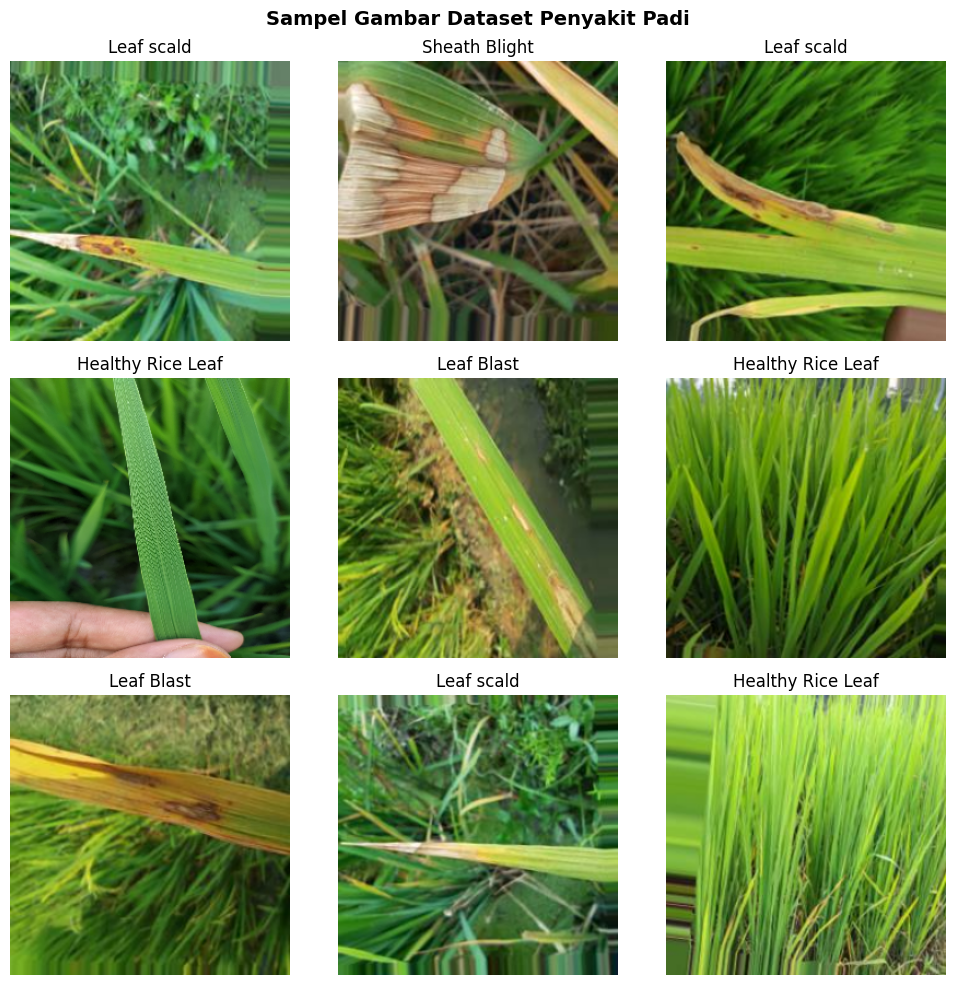

In [9]:
# ============================================================
# Tampilkan 9 sampel gambar dari dataset training
# ============================================================
# plt.figure() membuat kanvas gambar berukuran 10x10 inci
# Kita ambil 1 batch gambar lalu tampilkan 9 gambar pertama

plt.figure(figsize=(10, 10))

# Ambil 1 batch dari training dataset
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)       # Buat grid 3x3
        plt.imshow(images[i].numpy().astype("uint8"))  # Tampilkan gambar
        plt.title(class_names[labels[i]])   # Judul = nama kelas penyakit
        plt.axis("off")                     # Sembunyikan sumbu x dan y

plt.suptitle("Sampel Gambar Dataset Penyakit Padi", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## ⚡ BAGIAN 6: Optimasi Performa Dataset

Kita mengoptimalkan pipeline pembacaan data agar proses pelatihan lebih cepat menggunakan teknik **caching** dan **prefetching**.

In [10]:
# Optimasi pipeline data dengan caching dan prefetching

AUTOTUNE = tf.data.AUTOTUNE

# .cache()     : simpan data ke memori setelah epoch pertama → epoch berikutnya lebih cepat
# .prefetch()  : siapkan batch berikutnya saat GPU memproses batch saat ini
train_ds     = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds_final = val_ds_final.cache().prefetch(buffer_size=AUTOTUNE)
test_ds      = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

print("✅ Pipeline data dioptimalkan (cache + prefetch)!")
print("   train_ds, val_ds_final, dan test_ds siap digunakan.")

✅ Pipeline data dioptimalkan (cache + prefetch)!
   train_ds, val_ds_final, dan test_ds siap digunakan.


## 🧠 BAGIAN 7: Membangun Arsitektur Model CNN

Di sini kita membangun arsitektur model CNN (Convolutional Neural Network) secara bertahap.

**Alur data dalam CNN:**
```
Gambar Input (256x256x3)
       ↓
Rescaling (normalisasi pixel 0-255 → 0-1)
       ↓
Data Augmentation (flip, rotate, zoom)
       ↓
Conv2D + MaxPooling (ekstraksi fitur) × 3
       ↓
Flatten (ubah 3D → 1D)
       ↓
Dense (Fully Connected)
       ↓
Output (jumlah kelas penyakit)
```

In [11]:
# ============================================================
# Layer Augmentasi Data
# ============================================================
# Data augmentasi adalah teknik memperbanyak variasi data training dengan melakukan transformasi acak pada gambar.
# Tujuannya: mencegah overfitting dan membuat model lebih robust.

data_augmentation = keras.Sequential([
    # RandomFlip: membalik gambar secara acak (horizontal/vertikal)
    # → Model jadi tidak bergantung pada orientasi daun
    layers.RandomFlip("horizontal_and_vertical"),

    # RandomRotation: memutar gambar secara acak
    # 0.2 = rotasi maksimal 20% dari 360° = ±72°
    layers.RandomRotation(0.2),
], name="data_augmentation")

print("✅ Layer augmentasi data dibuat!")
print("   - RandomFlip    : Balik gambar acak (horizontal/vertikal)")
print("   - RandomRotation: Putar gambar acak ±72°")

✅ Layer augmentasi data dibuat!
   - RandomFlip    : Balik gambar acak (horizontal/vertikal)
   - RandomRotation: Putar gambar acak ±72°


In [12]:
# Membangun Model CNN Lengkap


model = keras.Sequential([

    # INPUT
    # Mendefinisikan bentuk input: gambar 256x256 dengan 3 channel warna (RGB)
    layers.InputLayer(input_shape=(IMG_SIZE, IMG_SIZE, 3)),

    # PREPROCESSING
    # Rescaling: mengubah nilai pixel dari rentang [0, 255] ke [0, 1]
    # Ini penting agar proses pelatihan lebih stabil dan cepat konvergen
    layers.Rescaling(1./255),

    # AUGMENTASI DATA
    # Diterapkan hanya saat training (saat inference/prediksi, augmentasi dimatikan)
    data_augmentation,

    # BLOK KONVOLUSI 1
    # Conv2D: mendeteksi fitur dasar seperti tepi, warna, tekstur sederhana
    # 16 = jumlah filter (detektor fitur)
    # (3,3) = ukuran kernel (jendela yang bergerak di atas gambar)
    # padding='same' = ukuran output sama dengan input
    # activation='relu' = fungsi aktivasi, menghilangkan nilai negatif
    layers.Conv2D(16, (3, 3), padding='same', activation='relu'),

    # MaxPooling2D: memperkecil ukuran gambar menjadi setengahnya
    # Mengambil nilai maksimum dari area 2x2 piksel
    # Manfaat: mengurangi komputasi & membuat model lebih robust terhadap posisi
    layers.MaxPooling2D(),

    # BLOK KONVOLUSI 2

    # 32 filter: mendeteksi fitur yang lebih kompleks (kombinasi fitur blok 1)
    # Misalnya: pola bercak, bentuk tepi yang lebih rumit
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D(),

    # BLOK KONVOLUSI 3
    # 64 filter: mendeteksi fitur tingkat tinggi
    # Misalnya: pola penyakit spesifik, kombinasi tekstur dan warna
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D(),

    # FLATTEN
    # Mengubah output 3D dari layer konvolusi (lebar x tinggi x filter)
    # menjadi array 1D (vektor datar) agar bisa masuk ke layer Dense
    layers.Flatten(),

    # FULLY CONNECTED (Dense) LAYER
    # 128 neuron: mengkombinasikan semua fitur yang sudah diekstrak
    # untuk membuat keputusan klasifikasi
    layers.Dense(128, activation='relu'),

    # OUTPUT LAYER
    # NUM_CLASSES neuron = jumlah kelas penyakit padi
    # Setiap neuron merepresentasikan skor untuk satu kelas
    # Kelas dengan skor tertinggi = hasil prediksi
    layers.Dense(NUM_CLASSES, name="output")

], name="CNN_RiceDiseaseClassifier")

print("✅ Arsitektur model CNN berhasil dibuat!")

✅ Arsitektur model CNN berhasil dibuat!


In [13]:

# Tampilkan ringkasan arsitektur model
# model.summary() menampilkan:
#   - Nama dan tipe setiap layer
#   - Ukuran output setiap layer
#   - Jumlah parameter (bobot) yang dapat dipelajari

model.summary()

Model: "CNN_RiceDiseaseClassifier"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 rescaling (Rescaling)       (None, 256, 256, 3)       0         
                                                                 
 data_augmentation (Sequenti  (None, 256, 256, 3)      0         
 al)                                                             
                                                                 
 conv2d (Conv2D)             (None, 256, 256, 16)      448       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 128, 128, 16)     0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 128, 128, 32)      4640      
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 64, 

## 🔧 BAGIAN 8: Kompilasi Model

Setelah arsitektur dibuat, kita perlu **mengkompilasi** model dengan menentukan:
- **Optimizer**: Algoritma untuk memperbarui bobot model
- **Loss Function**: Fungsi untuk mengukur seberapa salah prediksi model
- **Metrics**: Ukuran performa yang ingin kita pantau

In [14]:

# Kompilasi Model
model.compile(
    # Optimizer Adam: algoritma optimasi adaptif yang paling populer
    # Secara otomatis menyesuaikan learning rate selama pelatihan
    optimizer='adam',

    # SparseCategoricalCrossentropy: fungsi loss untuk klasifikasi multi-kelas
    # 'Sparse' = label berupa angka integer (0, 1, 2, ...) bukan one-hot
    # from_logits=True = output model belum melalui fungsi softmax
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),

    # Metrics yang dipantau selama pelatihan
    metrics=['accuracy']  # Akurasi = persentase prediksi yang benar
)

print("✅ Model berhasil dikompilasi!")
print("   - Optimizer : Adam")
print("   - Loss      : SparseCategoricalCrossentropy")
print("   - Metrics   : Accuracy")

✅ Model berhasil dikompilasi!
   - Optimizer : Adam
   - Loss      : SparseCategoricalCrossentropy
   - Metrics   : Accuracy


## 🏋️ BAGIAN 9: Pelatihan Model

Proses pelatihan dimulai! Model akan belajar selama **20 epoch**.

**Fitur tambahan**: Setiap epoch akan menampilkan **Precision, Recall, dan F1-Score** secara real-time menggunakan Custom Callback — bukan hanya accuracy dan loss.

> ⏱️ **Estimasi waktu**: Dengan GPU T4 di Colab, setiap epoch biasanya membutuhkan 1–3 menit.

In [15]:
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np

# ============================================================
# Custom Callback: tampilkan Precision, Recall, F1 setiap epoch
# ============================================================
# Keras hanya menampilkan accuracy & loss secara bawaan.
# Dengan callback ini, setelah setiap epoch kita evaluasi model
# pada val_ds_final dan cetak metrik tambahan.

class MetricsPerEpochCallback(tf.keras.callbacks.Callback):
    def __init__(self, val_dataset):
        super().__init__()
        self.val_dataset = val_dataset

    def on_epoch_end(self, epoch, logs=None):
        # Kumpulkan semua label dan prediksi dari validation set
        y_true, y_pred = [], []
        for images, labels in self.val_dataset:
            preds = self.model.predict(images, verbose=0)
            y_pred.extend(np.argmax(preds, axis=1))
            y_true.extend(labels.numpy())

        # Hitung metrik dengan average='macro' (rata-rata tiap kelas, tanpa pembobotan)
        precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
        recall    = recall_score(y_true, y_pred, average='macro', zero_division=0)
        f1        = f1_score(y_true, y_pred, average='macro', zero_division=0)

        print(f"   └─ val_precision: {precision:.4f}  |  val_recall: {recall:.4f}  |  val_f1: {f1:.4f}")

# Buat instance callback
metrics_cb = MetricsPerEpochCallback(val_ds_final)

# ============================================================
# Melatih Model
# ============================================================
history = model.fit(
    train_ds,
    validation_data=val_ds_final,
    epochs=EPOCHS,
    callbacks=[metrics_cb]   # ← tambahkan callback di sini
)

# 'history' menyimpan riwayat accuracy & loss setiap epoch
print("\n✅ Pelatihan selesai!")

Epoch 1/100


84/84 [==============================] - 303s 3s/step - loss: 1.7004 - accuracy: 0.2835 - val_loss: 1.4772 - val_accuracy: 0.3776
Epoch 2/100
84/84 [==============================] - 248s 3s/step - loss: 1.2819 - accuracy: 0.5009 - val_loss: 1.2558 - val_accuracy: 0.5052
Epoch 3/100
84/84 [==============================] - 240s 3s/step - loss: 1.0871 - accuracy: 0.5871 - val_loss: 1.1106 - val_accuracy: 0.5577
Epoch 4/100
84/84 [==============================] - 225s 3s/step - loss: 0.9838 - accuracy: 0.6319 - val_loss: 1.0709 - val_accuracy: 0.6206
Epoch 5/100
84/84 [==============================] - 210s 3s/step - loss: 0.9230 - accuracy: 0.6609 - val_loss: 1.1297 - val_accuracy: 0.5717
Epoch 6/100
84/84 [==============================] - 185s 2s/step - loss: 0.8582 - accuracy: 0.6811 - val_loss: 1.0811 - val_accuracy: 0.5822
Epoch 7/100
84/84 [==============================] - 184s 2s/step - loss: 0.8182 - accuracy: 0.7091 - val_loss: 1.0555 - val_accuracy: 0.5944
Epoch 8/100
84/84 

## 📈 BAGIAN 10: Visualisasi Hasil Pelatihan

Kita visualisasikan grafik akurasi dan loss selama pelatihan untuk melihat apakah model belajar dengan baik atau terjadi **overfitting** (model hafal data training tapi buruk di validasi).

In [16]:
# Ambil data riwayat pelatihan dari objek 'history'

acc     = history.history['accuracy']      # Akurasi training setiap epoch
val_acc = history.history['val_accuracy']  # Akurasi validasi setiap epoch
loss    = history.history['loss']          # Loss training setiap epoch
val_loss= history.history['val_loss']      # Loss validasi setiap epoch

print(f"Akurasi training akhir  : {acc[-1]*100:.2f}%")
print(f"Akurasi validasi akhir  : {val_acc[-1]*100:.2f}%")
print(f"Loss training akhir     : {loss[-1]:.4f}")
print(f"Loss validasi akhir     : {val_loss[-1]:.4f}")

Akurasi training akhir  : 98.88%
Akurasi validasi akhir  : 66.26%
Loss training akhir     : 0.0322
Loss validasi akhir     : 2.4422


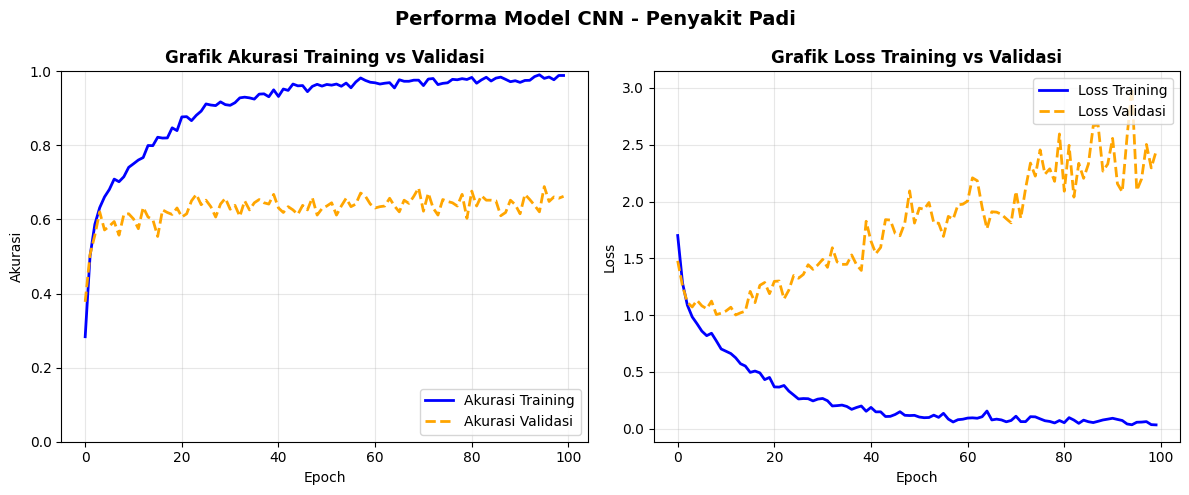

💾 Grafik disimpan: grafik_pelatihan.png


In [17]:

# Buat grafik Akurasi dan Loss

plt.figure(figsize=(12, 5))

# --- Grafik Akurasi ---
plt.subplot(1, 2, 1)
# plt.subplot(baris, kolom, posisi) = buat subplot di posisi ke-1
plt.plot(range(EPOCHS), acc,     label='Akurasi Training',  color='blue',  linewidth=2)
plt.plot(range(EPOCHS), val_acc, label='Akurasi Validasi',  color='orange', linewidth=2, linestyle='--')
plt.legend(loc='lower right')   # Tampilkan legenda di pojok kanan bawah
plt.title('Grafik Akurasi Training vs Validasi', fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Akurasi')
plt.ylim([0, 1])                # Skala sumbu Y dari 0 sampai 1
plt.grid(True, alpha=0.3)

# --- Grafik Loss ---
plt.subplot(1, 2, 2)
plt.plot(range(EPOCHS), loss,     label='Loss Training',  color='blue',   linewidth=2)
plt.plot(range(EPOCHS), val_loss, label='Loss Validasi',  color='orange',  linewidth=2, linestyle='--')
plt.legend(loc='upper right')   # Tampilkan legenda di pojok kanan atas
plt.title('Grafik Loss Training vs Validasi', fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, alpha=0.3)

plt.suptitle('Performa Model CNN - Penyakit Padi', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('grafik_pelatihan.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 Grafik disimpan: grafik_pelatihan.png")

## 🧪 BAGIAN 10b: Evaluasi Final pada Test Set

Setelah training selesai, kita evaluasi model pada **test set** — data yang belum pernah dilihat model sama sekali.
Ini adalah evaluasi yang paling jujur dan objektif.


In [18]:
# ============================================================
# Evaluasi Final pada Test Set
# ============================================================
# model.evaluate() mengukur performa pada data yang TIDAK digunakan saat training

print("=" * 60)
print("       EVALUASI FINAL PADA TEST SET")
print("=" * 60)

test_loss, test_acc = model.evaluate(test_ds, verbose=1)

print(f"\n📊 Hasil Evaluasi Test Set:")
print(f"   Test Loss     : {test_loss:.4f}")
print(f"   Test Accuracy : {test_acc*100:.2f}%")
print("=" * 60)
print("""
📖 Catatan:
   Test set = data yang 100% tidak digunakan selama training & validasi.
   Ini adalah ukuran performa model yang sesungguhnya di dunia nyata.
""")

       EVALUASI FINAL PADA TEST SET
18/18 [==============================] - 6s 258ms/step - loss: 2.3729 - accuracy: 0.6441

📊 Hasil Evaluasi Test Set:
   Test Loss     : 2.3729
   Test Accuracy : 64.41%

📖 Catatan:
   Test set = data yang 100% tidak digunakan selama training & validasi.
   Ini adalah ukuran performa model yang sesungguhnya di dunia nyata.



## 🔍 BAGIAN 11: Visualisasi Hasil Prediksi

Kita tampilkan beberapa gambar dari test set beserta prediksi model vs label sebenarnya.

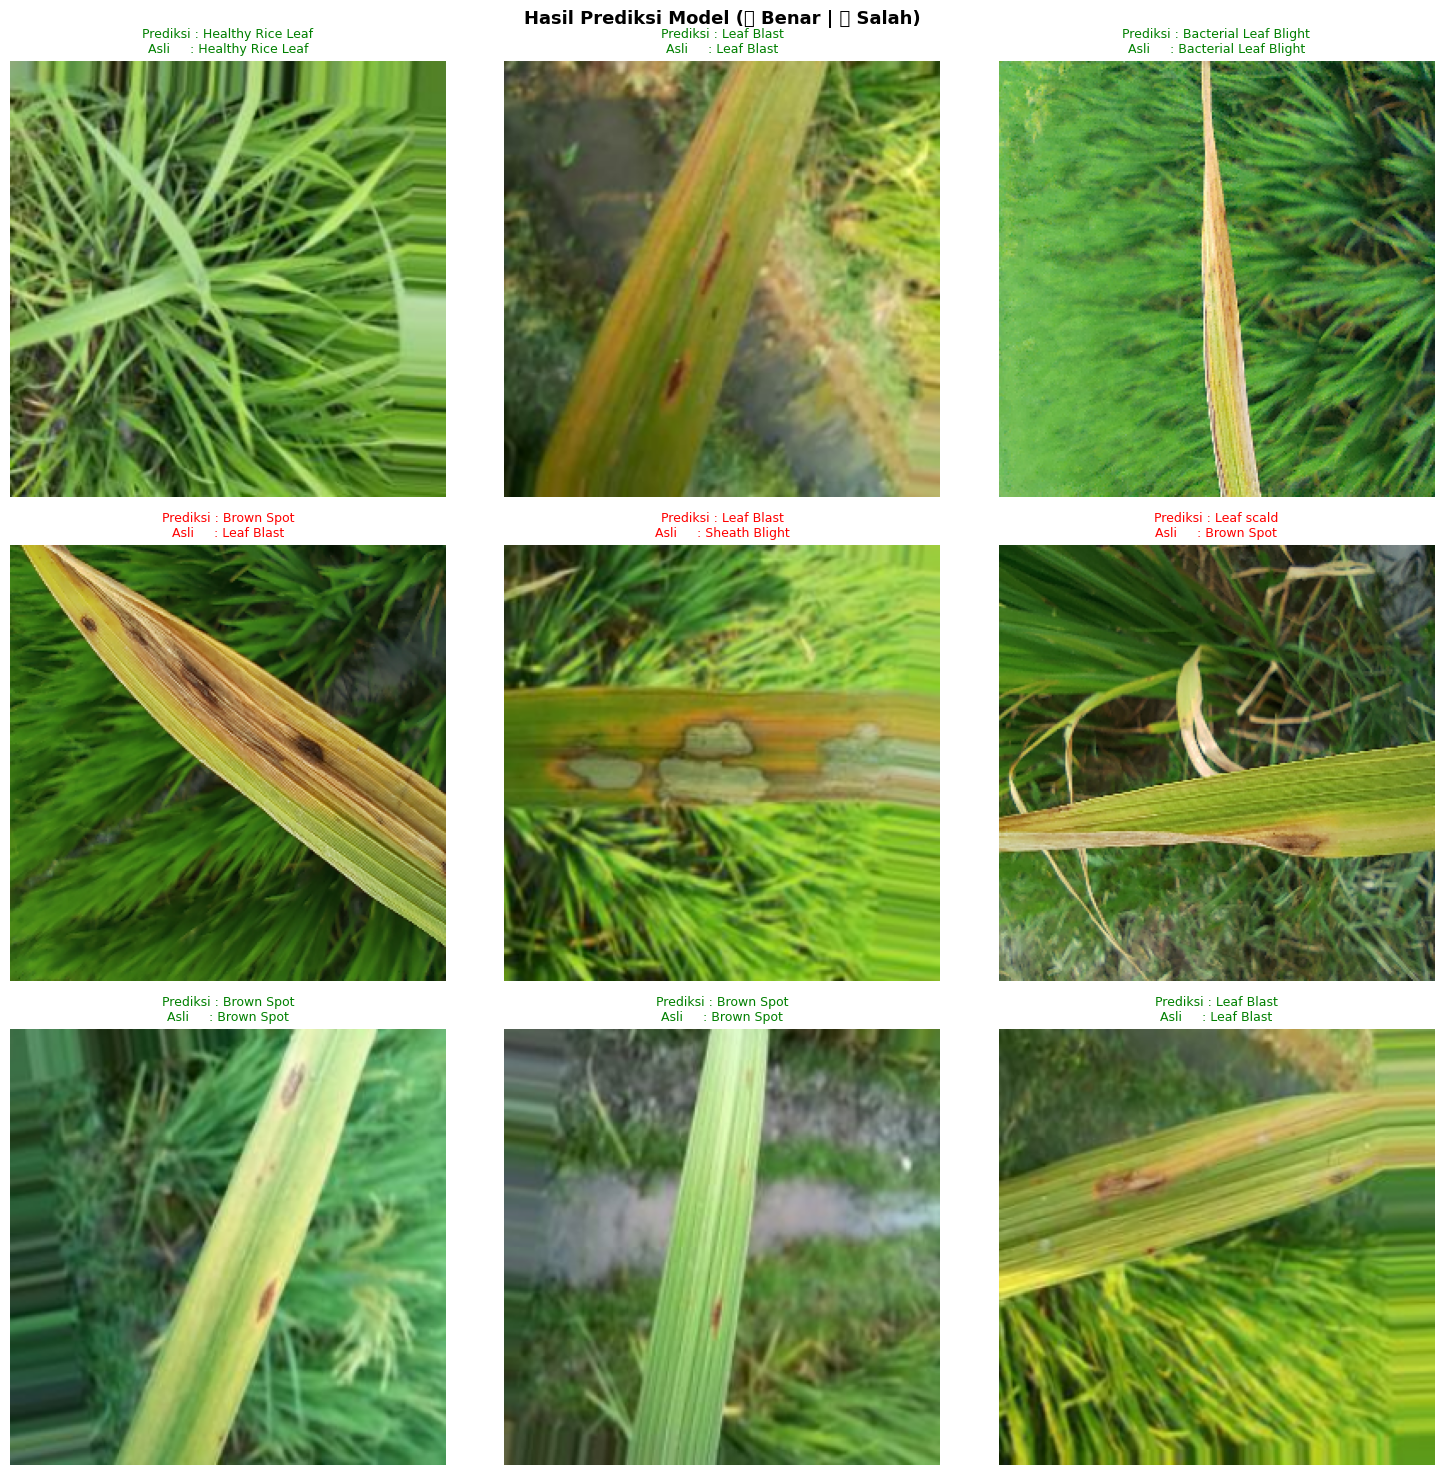

💾 Gambar disimpan: hasil_prediksi.png


In [19]:
# Tampilkan hasil prediksi pada gambar test

plt.figure(figsize=(15, 15))

# Ambil 1 batch dari test dataset
for images, labels in test_ds.take(1):

    # Jalankan model pada batch gambar test
    # Output: skor untuk setiap kelas (belum dinormalisasi)
    classifications = model(images)

    # Tampilkan 9 gambar pertama dalam grid 3x3
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))  # Tampilkan gambar asli

        # np.argmax() mengambil indeks nilai tertinggi
        # = kelas dengan skor prediksi tertinggi
        index_prediksi = np.argmax(classifications[i])
        nama_prediksi  = class_names[index_prediksi]  # Nama kelas prediksi
        nama_asli      = class_names[labels[i]]       # Nama kelas sebenarnya

        # Beri warna judul: hijau jika benar, merah jika salah
        warna = 'green' if nama_prediksi == nama_asli else 'red'
        plt.title(
            f"Prediksi : {nama_prediksi}\nAsli     : {nama_asli}",
            color=warna, fontsize=9
        )
        plt.axis("off")

plt.suptitle("Hasil Prediksi Model (🟢 Benar | 🔴 Salah)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('hasil_prediksi.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 Gambar disimpan: hasil_prediksi.png")

## 📊 BAGIAN 12: Confusion Matrix

**Confusion Matrix** adalah tabel yang menunjukkan performa model secara detail per kelas:
- **Diagonal (kiri-atas ke kanan-bawah)**: Prediksi yang benar
- **Di luar diagonal**: Prediksi yang salah (misklasifikasi)

Semakin gelap warna diagonal, semakin baik performa model.

In [20]:
# Kumpulkan semua prediksi dan label sebenarnya dari test set

semua_prediksi = []  # Menyimpan semua hasil prediksi model
semua_label    = []  # Menyimpan semua label sebenarnya

# Iterasi melalui seluruh test dataset batch per batch
for images, labels in test_ds:
    classifications = model(images)  # Prediksi model

    # np.argmax: ambil indeks kelas dengan skor tertinggi dari setiap gambar
    prediksi_batch = [np.argmax(clf) for clf in classifications.numpy()]

    semua_prediksi.extend(prediksi_batch)    # Tambahkan ke list utama
    semua_label.extend(labels.numpy())       # Tambahkan label asli

print(f"✅ Total gambar test yang dievaluasi: {len(semua_label)}")

✅ Total gambar test yang dievaluasi: 576


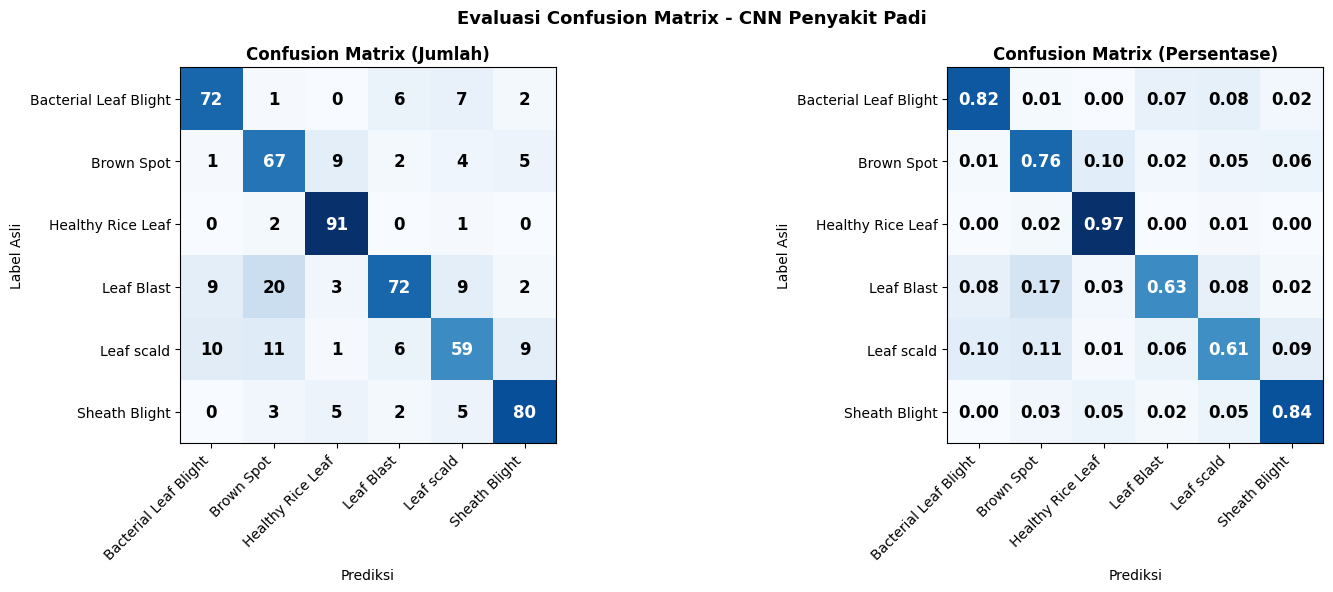

💾 Gambar disimpan: confusion_matrix.png


In [21]:
# Buat dan tampilkan Confusion Matrix

# confusion_matrix() dari sklearn menghitung jumlah prediksi
# yang benar dan salah untuk setiap kombinasi kelas
conf_matrix = confusion_matrix(semua_label, semua_prediksi)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Confusion Matrix Jumlah ---
axes[0].imshow(conf_matrix, interpolation='nearest', cmap=plt.cm.Blues)
axes[0].set_title('Confusion Matrix (Jumlah)', fontweight='bold')
tick_marks = np.arange(len(class_names))
axes[0].set_xticks(tick_marks); axes[0].set_xticklabels(class_names, rotation=45, ha='right')
axes[0].set_yticks(tick_marks); axes[0].set_yticklabels(class_names)
axes[0].set_xlabel('Prediksi'); axes[0].set_ylabel('Label Asli')

# Tampilkan angka di dalam kotak
thresh = conf_matrix.max() / 2.
for i in range(conf_matrix.shape[0]):
    for j in range(conf_matrix.shape[1]):
        axes[0].text(j, i, format(conf_matrix[i, j], 'd'),
                     ha="center", va="center",
                     color="white" if conf_matrix[i, j] > thresh else "black",
                     fontsize=12, fontweight='bold')

# --- Confusion Matrix Normalisasi (%) ---
conf_norm = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]
axes[1].imshow(conf_norm, interpolation='nearest', cmap=plt.cm.Blues)
axes[1].set_title('Confusion Matrix (Persentase)', fontweight='bold')
axes[1].set_xticks(tick_marks); axes[1].set_xticklabels(class_names, rotation=45, ha='right')
axes[1].set_yticks(tick_marks); axes[1].set_yticklabels(class_names)
axes[1].set_xlabel('Prediksi'); axes[1].set_ylabel('Label Asli')

for i in range(conf_norm.shape[0]):
    for j in range(conf_norm.shape[1]):
        axes[1].text(j, i, f"{conf_norm[i, j]:.2f}",
                     ha="center", va="center",
                     color="white" if conf_norm[i, j] > 0.5 else "black",
                     fontsize=12, fontweight='bold')

plt.suptitle('Evaluasi Confusion Matrix - CNN Penyakit Padi', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 Gambar disimpan: confusion_matrix.png")

## 📋 BAGIAN 13: Classification Report

**Classification Report** menampilkan metrik evaluasi lengkap per kelas:
- **Precision**: Dari semua yang diprediksi kelas X, berapa persen yang benar?
- **Recall**: Dari semua gambar kelas X, berapa persen yang berhasil terdeteksi?
- **F1-Score**: Rata-rata harmonis dari Precision dan Recall
- **Support**: Jumlah gambar per kelas di test set

In [22]:
# ============================================================
# Tampilkan Classification Report
# ============================================================

from sklearn.metrics import classification_report

# classification_report() menghasilkan laporan metrik lengkap
# target_names = nama kelas yang akan ditampilkan di laporan
report = classification_report(
    semua_label,
    semua_prediksi,
    target_names=class_names
)

print("=" * 60)
print("       CLASSIFICATION REPORT - CNN Penyakit Padi")
print("=" * 60)
print(report)
print("=" * 60)
print("""
📖 Cara Membaca:
   Precision : Dari prediksi kelas X, berapa % yang benar?
   Recall    : Dari gambar kelas X, berapa % terdeteksi?
   F1-Score  : Rata-rata Precision & Recall (semakin tinggi semakin baik)
   Support   : Jumlah gambar test per kelas
""")

       CLASSIFICATION REPORT - CNN Penyakit Padi
                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.78      0.82      0.80        88
           Brown Spot       0.64      0.76      0.70        88
    Healthy Rice Leaf       0.83      0.97      0.90        94
           Leaf Blast       0.82      0.63      0.71       115
           Leaf scald       0.69      0.61      0.65        96
        Sheath Blight       0.82      0.84      0.83        95

             accuracy                           0.77       576
            macro avg       0.77      0.77      0.76       576
         weighted avg       0.77      0.77      0.76       576


📖 Cara Membaca:
   Precision : Dari prediksi kelas X, berapa % yang benar?
   Recall    : Dari gambar kelas X, berapa % terdeteksi?
   F1-Score  : Rata-rata Precision & Recall (semakin tinggi semakin baik)
   Support   : Jumlah gambar test per kelas



---
## 📝 Ringkasan Alur Kerja Notebook

| Bagian | Proses | Tujuan |
|--------|--------|--------|
| 1–2 | Mount Drive + Import Library | Persiapan lingkungan |
| 3–4 | Konfigurasi + Load Dataset (70/15/15) | Muat & bagi data: train/val/test |
| 5 | EDA | Pastikan data benar |
| 6 | Optimasi Pipeline | Percepat pelatihan |
| 7–8 | Bangun + Kompilasi Model | Definisikan arsitektur CNN |
| 9 | Training + Precision/Recall/F1 per Epoch | Model belajar, metrik tampil real-time |
| 10 | Visualisasi Training | Deteksi overfitting |
| 10b | **Evaluasi Final Test Set** | Ukur performa objektif di data baru |
| 11 | Visualisasi Prediksi | Lihat contoh hasil |
| 12–13 | Confusion Matrix + Report | Evaluasi performa lengkap |
| 14 | Simpan Model | Simpan hasil ke Drive |

> ✅ **Split data 70/15/15** memastikan test set benar-benar independen dan evaluasi akhir lebih valid.

In [23]:

# ============================================================
# Simpan ringkasan hasil khusus eksperimen 6 kelas tanpa Tungro
# ============================================================
from pathlib import Path
import pandas as pd
from sklearn.metrics import classification_report

REPORT_DIR = Path(r"C:/Users/farid/Downloads/archive (5)/rice_leaf_disease_project/reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

report_dict = classification_report(
    semua_label,
    semua_prediksi,
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)

report_text = classification_report(
    semua_label,
    semua_prediksi,
    target_names=class_names,
    zero_division=0,
)

report_path = REPORT_DIR / "classification_report_revised_notebook_6kelas_tanpa_tungro.txt"
summary_path = REPORT_DIR / "ringkasan_revised_notebook_6kelas_tanpa_tungro.csv"

report_path.write_text(report_text, encoding="utf-8")
summary = pd.DataFrame([{
    "experiment": "rice_disease_cnn_revised_6kelas_tanpa_tungro",
    "model": "CNN Kustom dari notebook revised",
    "num_classes": len(class_names),
    "excluded_class": "Tungro",
    "image_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "test_accuracy": report_dict["accuracy"],
    "precision_macro": report_dict["macro avg"]["precision"],
    "recall_macro": report_dict["macro avg"]["recall"],
    "f1_macro": report_dict["macro avg"]["f1-score"],
    "precision_weighted": report_dict["weighted avg"]["precision"],
    "recall_weighted": report_dict["weighted avg"]["recall"],
    "f1_weighted": report_dict["weighted avg"]["f1-score"],
}])
summary.to_csv(summary_path, index=False)

print("? Report disimpan ke:", report_path)
print("? Ringkasan disimpan ke:", summary_path)
display(summary)


? Report disimpan ke: C:\Users\farid\Downloads\archive (5)\rice_leaf_disease_project\reports\classification_report_revised_notebook_6kelas_tanpa_tungro.txt
? Ringkasan disimpan ke: C:\Users\farid\Downloads\archive (5)\rice_leaf_disease_project\reports\ringkasan_revised_notebook_6kelas_tanpa_tungro.csv


,experiment,model,num_classes,excluded_class,image_size,batch_size,epochs,test_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
0,rice_disease_cnn_revised_6kelas_tanpa_tungro,CNN Kustom dari notebook revised,6,Tungro,256,32,100,0.765625,0.765055,0.771734,0.76413,0.76791,0.765625,0.762172
